# 02 · Open Models, Transfer Learning and Fine-Tuning

This is a module of Neural Networks 1002 and it assumes modules 01 to 03, 05 and 09 to 10 of [Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/) (neuron, backprop, training well, CNNs, transformer, GPT from scratch).

Almost nobody trains a serious network from scratch any more. The usual starting point is a **checkpoint** (a file of trained weights) that somebody else published: an image network trained on ImageNet, a text encoder trained on a large corpus, a language model trained on trillions of words. This notebook is about using such checkpoints well:

* **what "open" really means** for a model, which licences exist, and why you must read the licence of a checkpoint *before* building a product on it;
* how to **load real pre-trained models** on a laptop, and what size, numerical precision and quantisation (storing weights with fewer bits) cost and buy;
* **transfer learning** measured properly: a linear probe on frozen features, fine-tuning only the last layers, and full fine-tuning, on an image task and a text task, with accuracy plotted against the number of labelled examples and against the number of trainable parameters;
* **parameter-efficient fine-tuning**: LoRA (low-rank adaptation) written from scratch, then with the `peft` library; adapters, QLoRA and distillation explained;
* **saving, loading and exporting**: `state_dict` versus whole-model pickle (and why pickle is unsafe), safetensors, checkpoints that resume training, ONNX (Open Neural Network Exchange) export checked with ONNX Runtime, and a model card;
* a **decision guide** and a licence and safety checklist.

Contents:

1. What "open" means: open source, open weights, open data, and the licences
2. Hubs and real pre-trained models on a CPU: size, precision and quantisation
3. Transfer learning, measured: image task (ResNet-18) and text task (a small BERT)
4. Parameter-efficient fine-tuning: LoRA from scratch and with `peft`, adapters, QLoRA, distillation
5. Saving, loading and exporting models
6. A decision guide and a checklist
7. Key takeaways, exercises and references

| Builds on | What we reuse |
|---|---|
| module 01 and 02 of [Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/): the neuron and backprop | a weight matrix, gradients, what `requires_grad` switches off |
| module 03 of [1001](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/): training well | train/test splits, learning rates, overfitting with few examples |
| module 05 of [1001](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/): CNNs | the first transfer-learning experiments (frozen versus fine-tuned ResNet); here we measure them against the number of labels instead of repeating them |
| modules 09 and 10 of [1001](https://neural-networks.academy.forwardforecasting.eu/): the transformer and LLMs (GPT from scratch) | attention layers whose `q` and `v` projections we will adapt with LoRA |
| module 01 of [Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/01-rlhf-and-alignment/): RLHF and alignment | why a base checkpoint is only the first step |
| module 12 of [1001](https://neural-networks.academy.forwardforecasting.eu/12-capstone-real-case/): capstone defect inspection | transfer learning on real photographs of manufactured parts, with the same ImageNet network |

This module does **not** repeat the basics of PyTorch, TensorFlow or Hugging Face loading; the Python 1001 course covers them in [AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/). Here we assume you can already run `AutoModel.from_pretrained(...)` and ask what is behind it.

**Where the toy differs from the real systems.** The tasks are small on purpose (a 10-class clothing task at 48x48 pixels and an 8-class intent task with at most 160 labelled sentences) and the text model is a 11 M-parameter BERT, not a billion-parameter language model. The numbers show the *shape* of the trade-offs, not what you would get with a production model and a real data set.

It needs a few small downloads the first time (about 45 MB for ResNet-18, 17 MB for the text model, 270 MB for DistilBERT, a few MB of data); all are cached, so later runs start immediately. The whole notebook ran in about 4 minutes in a clean 2-CPU environment.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/02_open_models_and_fine_tuning.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 4 minutes, with a peak memory of about 2.6 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'PIL': 'pillow',
    'huggingface_hub': 'huggingface_hub',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'onnx': 'onnx',
    'onnxruntime': 'onnxruntime',
    'pandas': 'pandas',
    'peft': 'peft',
    'safetensors': 'safetensors',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'torchvision': 'torchvision',
    'transformers': 'transformers',
    'onnxscript': 'onnxscript',
    'accelerate': 'accelerate',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings, logging, os
warnings.filterwarnings("ignore")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import io, time, copy, math, json, pickle, tempfile, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
T_START = time.time()
def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))
def size_mb(obj):
    buf = io.BytesIO(); torch.save(obj, buf); return buf.tell() / 1e6

## 1. What "open" means

"Open model" is used loosely. Three different things can be open, and a release can have any combination of them:

| Word | What is published | What you can do | Example of how it is used |
|---|---|---|---|
| **open source** (strict sense) | code under an [OSI-approved](https://opensource.org/licenses) licence (use, study, modify, share, for any purpose) | everything the licence lists | the PyTorch or Transformers code |
| **open weights** | the trained parameters (the checkpoint), usually with a licence that may restrict use | run it, fine-tune it, often redistribute it, within the licence | Llama, Gemma, most checkpoints on the Hugging Face Hub |
| **open data** | the training data and a description of how it was collected and filtered | audit it, reproduce the training, check for leaks and bias | few models, because data often carries copyright and privacy limits |

The **Open Source Initiative's Open Source AI Definition 1.0** ([OSAID 1.0](https://opensource.org/ai/open-source-ai-definition), October 2024) says that to count as open source, an AI system must give you the four freedoms (use, study, modify, share) and the *preferred form for making modifications*: the weights, the code used to train and run it, and **sufficiently detailed information about the data** used to train it. Many popular "open" models publish weights only, and by this definition they are *open weights*, not open source. That is not a judgement of quality; it tells you what you may rely on.

### Licences you will meet

| Licence | Typical use | What it lets you do | Watch out for |
|---|---|---|---|
| [Apache 2.0](https://www.apache.org/licenses/LICENSE-2.0) | DistilBERT, BERT, many small models and the code of most libraries | use, modify and redistribute, also commercially; includes a patent grant | keep the notice and state your changes |
| [MIT](https://opensource.org/license/mit) | many research models and datasets, for example Fashion-MNIST | almost anything, also commercially | keep the copyright notice; no warranty |
| [OpenRAIL](https://huggingface.co/blog/open_rail) (for example [BigScience RAIL for BLOOM](https://huggingface.co/spaces/bigscience/license)) | models released with behavioural restrictions | use and modify, also commercially, **but** you must not use it for the listed harmful purposes and must pass those restrictions on | it is not an OSI licence: the use restrictions are part of the licence |
| [Llama community licence](https://www.llama.com/llama3/license/) | Meta's Llama family | use and fine-tune, also commercially, below a user-count threshold | very large services need a separate licence; an acceptable-use policy applies; naming rules for derived models |
| [Gemma terms of use](https://ai.google.dev/gemma/terms) | Google's Gemma family | use and fine-tune, also commercially, under a prohibited-use policy | the terms must be passed on to those you distribute it to; they are not an OSI licence |
| [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) | many datasets, for example the one in the capstone (module 12 of Neural Networks 1001) | reuse with credit | credit the source |

These summaries are orientation, not legal advice: read the text of the licence you depend on, because the details (thresholds, naming rules, field-of-use limits, who is bound) differ and change between versions.

### Model cards and dataset cards

A **model card** (Mitchell et al., [2019](https://arxiv.org/abs/1810.03993)) is a short document that travels with a checkpoint: what it is for and not for, what data it was trained on, how it was evaluated (and on which groups), known limits and biases. A **dataset card** does the same for data ([Hugging Face guide to dataset cards](https://huggingface.co/docs/hub/datasets-cards), [model cards](https://huggingface.co/docs/hub/model-cards)). On the Hub they are the `README.md` of the repository, with a metadata header (licence, language, base model, datasets) that tools can read.

### Why the licence matters before you build

A fine-tuned model **inherits the obligations** of the checkpoint and the data it came from. Discovering after six months of work that your base model forbids commercial use, that your training data was non-commercial only, or that a restriction must be passed on to your customers is expensive. The next cell reads the licence field of the checkpoints and data sets used in this notebook straight from the Hub metadata, which is how you would check a candidate in practice (and a few well-known examples for comparison).

In [2]:
from huggingface_hub import HfApi
api = HfApi()
rows = []
models = ["distilbert/distilbert-base-uncased", "google/bert_uncased_L-4_H-256_A-4", "HuggingFaceTB/SmolLM2-135M",
          "mistralai/Mistral-7B-v0.1", "google/gemma-2-2b", "meta-llama/Llama-3.2-1B", "bigscience/bloom"]
datasets_ = ["PolyAI/banking77", "zalando-datasets/fashion_mnist"]
for kind, ids in [("model", models), ("dataset", datasets_)]:
    for i in ids:
        try:
            info = api.model_info(i) if kind == "model" else api.dataset_info(i)
            lic = info.card_data.license if info.card_data is not None else None
            lic = ", ".join(lic) if isinstance(lic, list) else lic
            gated = bool(getattr(info, "gated", False))
        except Exception as e:
            lic, gated = "(could not reach the Hub)", False
        rows.append((kind, i, lic, "yes" if gated else "no"))
print(pd.DataFrame(rows, columns=["kind", "repository", "licence field", "gated (click-through)"]).to_string(index=False))

   kind                         repository             licence field gated (click-through)
  model distilbert/distilbert-base-uncased                apache-2.0                    no
  model  google/bert_uncased_L-4_H-256_A-4                apache-2.0                    no
  model         HuggingFaceTB/SmolLM2-135M                apache-2.0                    no
  model          mistralai/Mistral-7B-v0.1                apache-2.0                    no
  model                  google/gemma-2-2b                     gemma                   yes
  model            meta-llama/Llama-3.2-1B                  llama3.2                   yes
  model                   bigscience/bloom bigscience-bloom-rail-1.0                    no
dataset                   PolyAI/banking77                 cc-by-4.0                    no
dataset     zalando-datasets/fashion_mnist                       mit                    no


**Reading.** The small encoders (DistilBERT, BERT-Mini, SmolLM2) and Mistral 7B carry plain Apache 2.0; Gemma and Llama carry their own licence identifiers (`gemma`, `llama3.2`) and are *gated*: you must accept their terms on the Hub before downloading, which is itself a sign that the licence has conditions to read; BLOOM carries an OpenRAIL licence. The two data sets are CC BY 4.0 and MIT. Note what this cell cannot tell you: the metadata field is a label, not the licence text, and it says nothing about the licences of the data the model was trained on. Open the licence file before you depend on it.

## 2. Hubs and real pre-trained models on a CPU

A **hub** is a registry where checkpoints, datasets and their cards are published and versioned; the Hugging Face Hub is the largest, and the `torchvision`, TensorFlow Hub and ONNX Model Zoo play similar roles for narrower families. Loading is one line, and the file is cached on disk the first time. Here we load [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased) (Sanh et al., [2019](https://arxiv.org/abs/1910.01108); licence Apache 2.0), a compressed BERT, and look at what we actually downloaded: how many parameters, how many bytes, and what each precision costs.

### Size, precision and quantisation

A weight is a number, and numbers can be stored with different numbers of bits:

| Format | Bytes per weight | Notes |
|---|---|---|
| float32 (fp32) | 4 | the default for training |
| bfloat16 / float16 | 2 | halves memory; training and inference on GPUs and newer CPUs |
| int8 | 1 | **quantisation**: weights stored as 8-bit integers plus a scale; the matrix products run in integer arithmetic |
| 4 bit | 0.5 | used by the large-model tooling (and by QLoRA, section 4); needs special kernels |

**Dynamic quantisation** (`torch.ao.quantization.quantize_dynamic`) converts the weights of the `nn.Linear` layers to int8 once, and quantises the activations on the fly at each call. It needs no data and no training, which is why it is the first thing to try for CPU inference. We measure the three things that matter: size on disk, speed, and whether the outputs still agree with the original.

In [3]:
from transformers import AutoTokenizer, AutoModel
t0 = time.time()
tok_d = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
distil = AutoModel.from_pretrained("distilbert/distilbert-base-uncased").eval()
print(f"loaded DistilBERT in {time.time() - t0:.1f} s, {count_params(distil) / 1e6:.1f} M parameters")

sentences = ["how do i top up my card", "my card payment was declined at the shop",
             "why was i charged a fee for a transfer", "i lost my phone, how do i freeze my account"] * 8   # 32 sentences
batch = tok_d(sentences, return_tensors="pt", padding=True)

def pooled(model, b):
    with torch.no_grad():
        h = model(**b).last_hidden_state
    m = b["attention_mask"].unsqueeze(-1).to(h.dtype)
    return ((h * m).sum(1) / m.sum(1)).float()

def latency(model, b, reps=3):
    pooled(model, b)                       # warm-up
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); pooled(model, b); ts.append(time.perf_counter() - t)
    return float(np.median(ts))

variants = {"fp32": distil,
            "bf16": copy.deepcopy(distil).to(torch.bfloat16),
            "int8 dynamic": torch.ao.quantization.quantize_dynamic(copy.deepcopy(distil), {nn.Linear}, dtype=torch.qint8)}
ref = pooled(distil, batch)
rows = []
for name, m in variants.items():
    out = pooled(m, batch)
    cos = F.cosine_similarity(out, ref, dim=1).mean().item()
    rows.append((name, size_mb(m.state_dict()), latency(m, batch) * 1000, cos))
q_table = pd.DataFrame(rows, columns=["precision", "size (MB)", "latency, 32 sentences (ms)", "cosine similarity to fp32"])
print(q_table.round(4).to_string(index=False))

loaded DistilBERT in 2.2 s, 66.4 M parameters


   precision  size (MB)  latency, 32 sentences (ms)  cosine similarity to fp32
        fp32   265.4880                    223.4750                     1.0000
        bf16   132.7622                    115.2785                     1.0000
int8 dynamic   138.1138                     83.4193                     0.9312


**Reading.** Half precision (bf16) halves the file (265 MB to 133 MB) and leaves the outputs identical at four decimals. Dynamic int8 shrinks it only to 138 MB (52 %, not 25 %), because dynamic quantisation converts the `nn.Linear` layers only and the 23 M-parameter word-embedding table stays in float32; the pooled sentence vectors move noticeably (cosine similarity 0.931 to the fp32 ones), so whether that matters depends on the task: section 4.5 measures it on a classifier. Speed is the hardware-dependent part. On the server CPU that produced the numbers above, bf16 was 1.9 times faster than fp32 (115 ms against 223 ms for 32 sentences) and int8 2.7 times faster (83 ms). On an older laptop CPU without fast bf16 arithmetic we measured the opposite for bf16: about four times *slower* than fp32, while int8 was still 1.5 times faster. So smaller is not automatically faster; measure on the machine you will deploy on.

## 3. Transfer learning, measured

Transfer learning means starting from weights learned on a large source task and adapting them to a small target task (Yosinski et al., [2014](https://arxiv.org/abs/1411.1792), measured how general the features of each layer are; Howard and Ruder, [2018](https://arxiv.org/abs/1801.06146), showed the recipe for text with ULMFiT). There is a ladder of choices, from cheapest to most expensive:

| Strategy | What is trained | Trainable parameters | Risk |
|---|---|---|---|
| **linear probe** (feature extraction) | only a new linear classifier on frozen features | tiny | features may not suit the new task |
| **fine-tune the last layers** | the top block(s) and the classifier | a fraction | needs choosing how many layers |
| **full fine-tuning** | everything | all | overfits tiny data sets; needs a small learning rate; one full copy per task |
| **train from scratch** | everything, from random weights | all | needs far more data (we measure how much) |

Module 05 of [Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) showed frozen and fine-tuned ResNet features once, and the capstone (module 12 of 1001) applies them to real photographs. Here the question is different: **how do the strategies compare as the number of labelled examples grows from a handful to a few hundred, and what does each one cost in trainable parameters?** Every strategy sees the *same* nested subsets of the training data and the same test set. Fixed seed and a single run per cell, so differences of two or three points are inside the noise (we estimate it below).

### 3.1 The image task: ImageNet ResNet-18 on clothing photographs

The network is `torchvision`'s **ResNet-18** (He et al., [2015](https://arxiv.org/abs/1512.03385)) with its `IMAGENET1K_V1` weights ([documentation](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)). The torchvision *code* is BSD-3 licensed; the *weights* were trained on ImageNet, whose [terms](https://www.image-net.org/download.php) restrict use to non-commercial research and education: a good example of a checkpoint whose licence is stricter than the library that serves it, which you would have to settle before shipping a product.

The data is **Fashion-MNIST** (Xiao et al., [2017](https://arxiv.org/abs/1708.07747); [dataset card](https://huggingface.co/datasets/zalando-datasets/fashion_mnist), MIT licence): 28x28 grey images of ten clothing classes. We upsample to 48x48 and repeat the channel three times. This is a deliberately *different domain* from ImageNet (small grey silhouettes, not colour photographs), so the transfer is not trivial. Training sets use 2, 5, 10 and 30 images per class (20, 50, 100 and 300 in total), nested so that each is a prefix of the next; the test set is 1000 fixed images (100 per class).

test: (1000, 3, 48, 48)  largest training set: (300, 3, 48, 48)


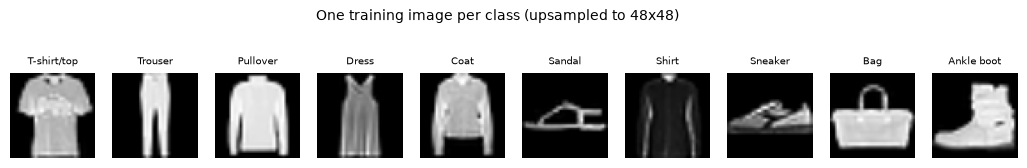

In [4]:
import torchvision
from huggingface_hub import hf_hub_download
from PIL import Image

FM_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def fm_split(split):
    p = hf_hub_download("zalando-datasets/fashion_mnist", f"fashion_mnist/{split}-00000-of-00001.parquet", repo_type="dataset")
    return pd.read_parquet(p)

df_tr, df_te = fm_split("train"), fm_split("test")
rng = np.random.default_rng(0)
IMG_SIZES = [2, 5, 10, 30]                       # images per class
order = {c: rng.permutation(np.where(df_tr.label.values == c)[0]) for c in range(10)}
test_idx = np.concatenate([rng.permutation(np.where(df_te.label.values == c)[0])[:100] for c in range(10)])
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_tensor(df, idx):
    x = np.stack([np.array(Image.open(io.BytesIO(df.image.iloc[i]["bytes"]))) for i in idx]).astype(np.float32) / 255
    x = F.interpolate(torch.from_numpy(x).unsqueeze(1), size=48, mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
    return (x - MEAN) / STD

def img_subset(k):
    idx = np.concatenate([order[c][:k] for c in range(10)])
    return to_tensor(df_tr, idx), torch.tensor(df_tr.label.values[idx])

Xte_img, yte_img = to_tensor(df_te, test_idx), torch.tensor(df_te.label.values[test_idx])
X30, y30 = img_subset(30)
print("test:", tuple(Xte_img.shape), " largest training set:", tuple(X30.shape))
fig, axes = plt.subplots(1, 10, figsize=(13, 1.7))
for c, ax in enumerate(axes):
    ax.imshow((X30[y30 == c][0, 0] * 0.226 + 0.449).numpy(), cmap="gray"); ax.set_title(FM_NAMES[c], fontsize=7); ax.axis("off")
plt.suptitle("One training image per class (upsampled to 48x48)", y=1.12, fontsize=10); plt.show()

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def make_resnet(pretrained):
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(512, 10)
    return m

@torch.no_grad()
def evaluate(model, X, y, bs=250):
    model.eval()
    return float(np.mean(np.concatenate([model(X[i:i + bs]).argmax(1).numpy() == y[i:i + bs].numpy() for i in range(0, len(X), bs)])))

def features(model, X, bs=250):
    fc, model.fc = model.fc, nn.Identity()
    model.eval()
    with torch.no_grad():
        f = torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)]).numpy()
    model.fc = fc
    return f

def run_image(strategy, k, seed=0):
    # strategies: probe, last (layer4 + fc), full (all, pretrained), scratch (all, random init)
    torch.manual_seed(seed)
    X, y = img_subset(k)
    model = make_resnet(strategy != "scratch")
    t = time.time()
    if strategy == "probe":
        sc = StandardScaler().fit(features(model, X))
        clf = LogisticRegression(C=1.0, max_iter=3000).fit(sc.transform(features(model, X)), y.numpy())
        acc = float((clf.predict(sc.transform(features(model, Xte_img))) == yte_img.numpy()).mean())
        return dict(strategy=strategy, k=k, n=len(X), trainable=512 * 10 + 10, acc=acc, seconds=time.time() - t, model=None)
    for p in model.parameters():
        p.requires_grad = strategy in ("full", "scratch")
    for p in model.fc.parameters():
        p.requires_grad = True
    if strategy == "last":
        for p in model.layer4.parameters():
            p.requires_grad = True
    backbone_lr = {"last": 2e-4, "full": 1e-4, "scratch": 1e-3}[strategy]
    groups = [{"params": model.fc.parameters(), "lr": 1e-3}]
    bb = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("fc.")]
    if bb:
        groups.append({"params": bb, "lr": backbone_lr})
    opt = torch.optim.Adam(groups)
    steps_per_epoch = math.ceil(len(X) / 32)
    epochs = max(4, math.ceil(30 / steps_per_epoch))
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train() if strategy in ("full", "scratch") else model.eval()      # frozen BatchNorm statistics unless everything trains
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), 32):
            b = perm[i:i + 32]
            loss = F.cross_entropy(model(X[b]), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return dict(strategy=strategy, k=k, n=len(X), trainable=count_params(model, True), acc=evaluate(model, Xte_img, yte_img),
                seconds=time.time() - t, model=model if k == IMG_SIZES[-1] else None)

img_results = []
for strategy in ["probe", "last", "full", "scratch"]:
    for k in IMG_SIZES:
        r = run_image(strategy, k)
        img_results.append(r)
        print(f"{strategy:8s} {r['n']:4d} labelled images  trainable {r['trainable']:>10,d}  test accuracy {r['acc']:.3f}  ({r['seconds']:.0f} s)")
img_df = pd.DataFrame([{k: v for k, v in r.items() if k != "model"} for r in img_results])
IMG_MODELS = {r["strategy"]: r["model"] for r in img_results if r["model"] is not None}

probe      20 labelled images  trainable      5,130  test accuracy 0.551  (1 s)


probe      50 labelled images  trainable      5,130  test accuracy 0.687  (1 s)


probe     100 labelled images  trainable      5,130  test accuracy 0.721  (1 s)


probe     300 labelled images  trainable      5,130  test accuracy 0.762  (2 s)


last       20 labelled images  trainable  8,398,858  test accuracy 0.538  (3 s)


last       50 labelled images  trainable  8,398,858  test accuracy 0.697  (3 s)


... (6 outputs left out)

scratch    20 labelled images  trainable 11,181,642  test accuracy 0.478  (5 s)


scratch    50 labelled images  trainable 11,181,642  test accuracy 0.675  (5 s)


scratch   100 labelled images  trainable 11,181,642  test accuracy 0.689  (5 s)


scratch   300 labelled images  trainable 11,181,642  test accuracy 0.739  (7 s)


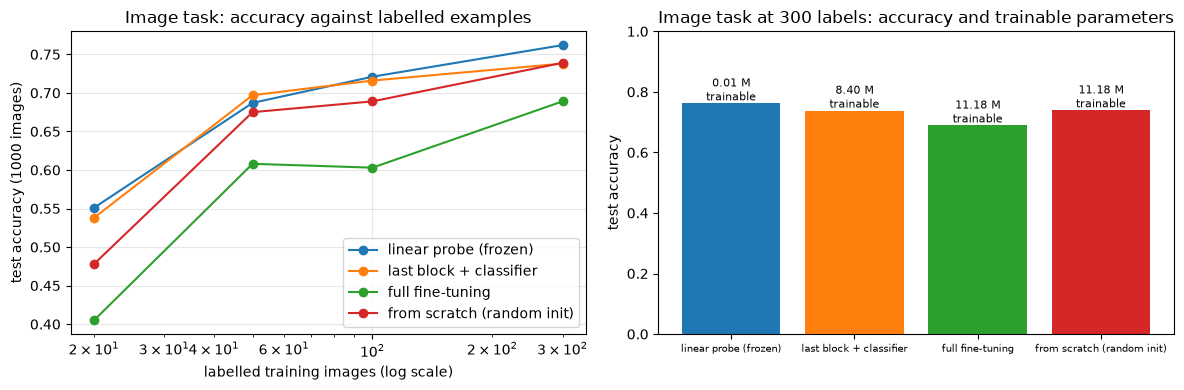

In [6]:
colors = {"probe": "tab:blue", "last": "tab:orange", "full": "tab:green", "scratch": "tab:red"}
labels = {"probe": "linear probe (frozen)", "last": "last block + classifier", "full": "full fine-tuning", "scratch": "from scratch (random init)"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s in colors:
    d = img_df[img_df.strategy == s]
    axes[0].plot(d.n, d.acc, "o-", color=colors[s], label=labels[s])
axes[0].set_xscale("log"); axes[0].set_xlabel("labelled training images (log scale)"); axes[0].set_ylabel("test accuracy (1000 images)")
axes[0].set_title("Image task: accuracy against labelled examples"); axes[0].legend(); axes[0].grid(alpha=0.3)
d = img_df[img_df.n == 300]
axes[1].bar([labels[s] for s in d.strategy], d.acc, color=[colors[s] for s in d.strategy])
for i, (a, tr) in enumerate(zip(d.acc, d.trainable)):
    axes[1].text(i, a + 0.01, f"{tr / 1e6:.2f} M\ntrainable", ha="center", fontsize=8)
axes[1].set_ylim(0, 1.0); axes[1].set_ylabel("test accuracy"); axes[1].set_title("Image task at 300 labels: accuracy and trainable parameters")
axes[1].tick_params(axis="x", labelsize=7); plt.tight_layout(); plt.show()

**Reading.** Accuracies for 20, 50, 100 and 300 labelled images. Linear probe: 0.551, 0.687, 0.721, 0.762. Last block plus classifier: 0.538, 0.697, 0.716, 0.738. Full fine-tuning: 0.405, 0.608, 0.603, 0.689. From scratch: 0.478, 0.675, 0.689, 0.739. The test set has 1000 images (a standard error of about 1.4 points) and every cell is one run on one seed, so with training sets this small, differences below 3 or 4 points are not reliable (the full and scratch rows also moved by a point or two between two runs of this notebook, because multi-threaded arithmetic is not bit-reproducible). Three things are nevertheless clear. First, the **linear probe, with only 5,130 trainable parameters, is the best or tied for best at every size**, and it is also the cheapest by far. Second, **pre-training helped only with the fewest labels**: at 20 images the probe beats training from scratch by 7 points; by 50 images the advantage is gone (0.687 against 0.675, within noise). Third, **full fine-tuning was the worst option at every size here, and below training from scratch from 50 images on**. This is a negative result and we should not over-read it: the domain is far from ImageNet (grey 48x48 silhouettes against colour photographs), we updated all 11 M weights with very few steps and batches of 32, and we tuned no hyper-parameters. It does not contradict module 12 of Neural Networks 1001, where fine-tuning helped on real photographs; it shows that fine-tuning is not free and has to be measured against the probe. Where the toy differs: 300 images at 48x48 pixels on one seed, not a real data set.

### 3.2 The text task: a small pre-trained encoder on banking questions

For text we use **BERT-Mini** (Turc et al., [2019](https://arxiv.org/abs/1908.08962); [model page](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4), Apache 2.0): 4 transformer layers of width 256, 11 M parameters, small enough to fine-tune on a laptop in seconds. The data is **Banking77** (Casanueva et al., [2020](https://arxiv.org/abs/2003.04807); [dataset card](https://huggingface.co/datasets/PolyAI/banking77), CC BY 4.0): short customer questions, each labelled with one of 77 intents. We keep **8 intents** chosen at random with a fixed seed, and train on 2, 5, 10 and 20 sentences per class (16, 40, 80 and 160 labelled sentences); the test set is the 320 official test sentences of those 8 intents. The sentence vector is the mean of the encoder's output over the tokens, and the classifier is a linear layer on top, exactly the structure of the image task.

In [7]:
from transformers import AutoTokenizer, AutoModel
from huggingface_hub import DatasetCard

card = DatasetCard.load("PolyAI/banking77")
_nm = card.data.to_dict()["dataset_info"]["features"][1]["dtype"]["class_label"]["names"]
ALL_NAMES = [_nm[str(i)] for i in range(77)]
tr_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/train-00000-of-00001.parquet", repo_type="dataset"))
te_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/test-00000-of-00001.parquet", repo_type="dataset"))
rng = np.random.default_rng(1)
CLS = sorted(rng.choice(77, size=8, replace=False).tolist())
remap = {c: i for i, c in enumerate(CLS)}
TXT_NAMES = [ALL_NAMES[c] for c in CLS]
print("the 8 intents:", TXT_NAMES)
tr_b = tr_b[tr_b.label.isin(CLS)].reset_index(drop=True); te_b = te_b[te_b.label.isin(CLS)].reset_index(drop=True)
tr_b["y"] = tr_b.label.map(remap); te_b["y"] = te_b.label.map(remap)
TXT_SIZES = [2, 5, 10, 20]
order_t = {c: rng.permutation(np.where(tr_b.y.values == c)[0]) for c in range(8)}
def txt_subset(k):
    idx = np.concatenate([order_t[c][:k] for c in range(8)])
    return tr_b.text.values[idx].tolist(), torch.tensor(tr_b.y.values[idx])
te_text, te_y = te_b.text.tolist(), torch.tensor(te_b.y.values)
print(f"unlabelled pool: {len(tr_b)} training sentences in total, test: {len(te_text)} sentences")
print("example:", tr_b.text.iloc[0], "->", TXT_NAMES[tr_b.y.iloc[0]])

BERT = "google/bert_uncased_L-4_H-256_A-4"
tok = AutoTokenizer.from_pretrained(BERT)
def tokens(texts):
    return tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=32)

class TextClf(nn.Module):
    def __init__(self, encoder, n_classes=8):
        super().__init__()
        self.enc = encoder
        self.head = nn.Linear(encoder.config.hidden_size, n_classes)
    def embed(self, b):
        h = self.enc(**b).last_hidden_state
        m = b["attention_mask"].unsqueeze(-1).to(h.dtype)
        return (h * m).sum(1) / m.sum(1)
    def forward(self, b):
        return self.head(self.embed(b))

@torch.no_grad()
def predict(model, texts, bs=160):
    model.eval()
    return torch.cat([model(tokens(texts[i:i + bs])).argmax(1) for i in range(0, len(texts), bs)])

the 8 intents: ['apple_pay_or_google_pay', 'card_acceptance', 'exchange_via_app', 'fiat_currency_support', 'supported_cards_and_currencies', 'topping_up_by_card', 'verify_my_identity', 'visa_or_mastercard']
unlabelled pool: 900 training sentences in total, test: 320 sentences
example: How many different currencies can I hold money in? -> fiat_currency_support


In [8]:
def run_text(strategy, k, seed=0, lora_impl="peft", keep=False):
    # strategies: probe, last (last transformer layer + head), full, lora (r=8 on query and value)
    torch.manual_seed(seed)
    texts, y = txt_subset(k)
    enc = AutoModel.from_pretrained(BERT)
    t = time.time()
    if strategy == "probe":
        model = TextClf(enc)
        model.eval()
        with torch.no_grad():
            f_tr, f_te = model.embed(tokens(texts)).numpy(), torch.cat([model.embed(tokens(te_text[i:i + 160])) for i in range(0, len(te_text), 160)]).numpy()
        sc = StandardScaler().fit(f_tr)
        clf = LogisticRegression(C=1.0, max_iter=3000).fit(sc.transform(f_tr), y.numpy())
        acc = float((clf.predict(sc.transform(f_te)) == te_y.numpy()).mean())
        return dict(strategy=strategy, k=k, n=len(texts), trainable=256 * 8 + 8, acc=acc, seconds=time.time() - t, model=None)
    for p in enc.parameters():
        p.requires_grad = strategy == "full"
    if strategy == "last":
        for p in enc.encoder.layer[-1].parameters():
            p.requires_grad = True
    if strategy == "lora":
        if lora_impl == "peft":
            from peft import LoraConfig, get_peft_model
            enc = get_peft_model(enc, LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0, target_modules=["query", "value"]))
        else:
            add_lora(enc, r=8, alpha=16)
    model = TextClf(enc)
    lr = {"last": 3e-4, "full": 1e-4, "lora": 1e-3}[strategy]
    opt = torch.optim.Adam([{"params": model.head.parameters(), "lr": 2e-3},
                            {"params": [p for p in model.enc.parameters() if p.requires_grad], "lr": lr}])
    steps_per_epoch = math.ceil(len(texts) / 16)
    epochs = max(6, math.ceil(45 / steps_per_epoch))
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(texts), generator=g)
        for i in range(0, len(texts), 16):
            b = perm[i:i + 16]
            loss = F.cross_entropy(model(tokens([texts[j] for j in b])), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    acc = float((predict(model, te_text) == te_y).float().mean())
    return dict(strategy=strategy, k=k, n=len(texts), trainable=count_params(model, True), acc=acc, seconds=time.time() - t,
                model=model if keep else None)

Before running the text experiment we need LoRA, because it is the fourth strategy in the comparison. The next section explains it; the code is the minimum needed here, and section 4 opens it up. The idea in one line: freeze the pre-trained weight matrix $W$ and learn a **low-rank correction** $\Delta W = \frac{\alpha}{r} B A$, where $A$ has shape $r \times d_{in}$, $B$ has shape $d_{out} \times r$, and the rank $r$ is much smaller than the layer width. Only $A$ and $B$ are trained: $r(d_{in} + d_{out})$ parameters instead of $d_{in} d_{out}$.

In [9]:
class LoRALinear(nn.Module):
    # y = x W^T + b  +  (alpha / r) * x A^T B^T      (W, b frozen; A and B trained; B starts at zero)
    def __init__(self, base: nn.Linear, r=8, alpha=16):
        super().__init__()
        self.base, self.r, self.scale = base, r, alpha / r
        for p in self.base.parameters():
            p.requires_grad = False
        self.A = nn.Parameter(torch.empty(r, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T) @ self.B.T
    @torch.no_grad()
    def merged(self):
        lin = copy.deepcopy(self.base)
        lin.weight += self.scale * self.B @ self.A
        return lin

def add_lora(bert, r=8, alpha=16):
    for layer in bert.encoder.layer:
        sa = layer.attention.self
        sa.query, sa.value = LoRALinear(sa.query, r, alpha), LoRALinear(sa.value, r, alpha)

In [10]:
txt_results = []
for strategy in ["probe", "last", "lora", "full"]:
    for k in TXT_SIZES:
        r = run_text(strategy, k, keep=(strategy == "full" and k == TXT_SIZES[-1]))
        txt_results.append(r)
        print(f"{strategy:6s} {r['n']:4d} labelled sentences  trainable {r['trainable']:>10,d}  test accuracy {r['acc']:.3f}  ({r['seconds']:.0f} s)")
txt_df = pd.DataFrame([{k: v for k, v in r.items() if k != "model"} for r in txt_results])
TEACHER = next(r["model"] for r in txt_results if r["model"] is not None)

probe    16 labelled sentences  trainable      2,056  test accuracy 0.613  (0 s)


probe    40 labelled sentences  trainable      2,056  test accuracy 0.756  (0 s)


probe    80 labelled sentences  trainable      2,056  test accuracy 0.794  (1 s)


probe   160 labelled sentences  trainable      2,056  test accuracy 0.872  (1 s)


last     16 labelled sentences  trainable    791,816  test accuracy 0.550  (2 s)


last     40 labelled sentences  trainable    791,816  test accuracy 0.706  (2 s)


... (6 outputs left out)

full     16 labelled sentences  trainable 11,172,616  test accuracy 0.584  (5 s)


full     40 labelled sentences  trainable 11,172,616  test accuracy 0.734  (5 s)


full     80 labelled sentences  trainable 11,172,616  test accuracy 0.797  (5 s)


full    160 labelled sentences  trainable 11,172,616  test accuracy 0.903  (7 s)


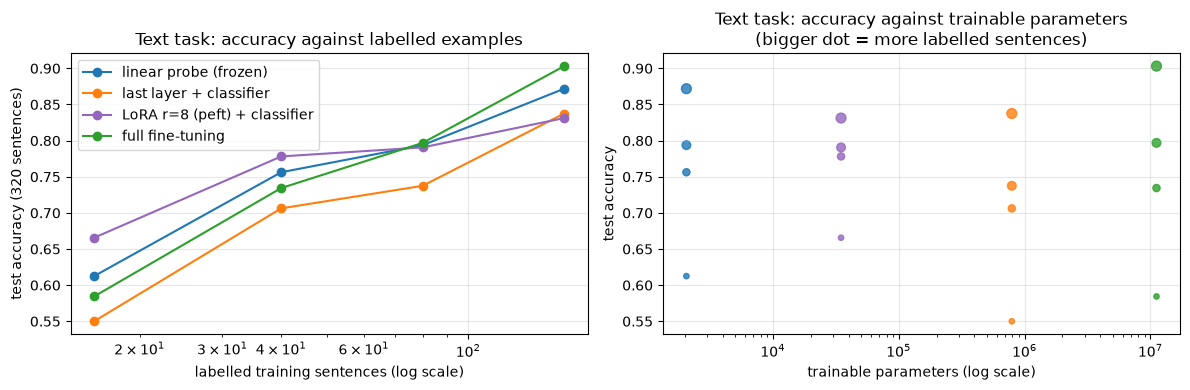

In [11]:
tcolors = {"probe": "tab:blue", "last": "tab:orange", "lora": "tab:purple", "full": "tab:green"}
tlabels = {"probe": "linear probe (frozen)", "last": "last layer + classifier", "lora": "LoRA r=8 (peft) + classifier", "full": "full fine-tuning"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s in tcolors:
    d = txt_df[txt_df.strategy == s]
    axes[0].plot(d.n, d.acc, "o-", color=tcolors[s], label=tlabels[s])
axes[0].set_xscale("log"); axes[0].set_xlabel("labelled training sentences (log scale)"); axes[0].set_ylabel("test accuracy (320 sentences)")
axes[0].set_title("Text task: accuracy against labelled examples"); axes[0].legend(); axes[0].grid(alpha=0.3)
for s in tcolors:
    d = txt_df[txt_df.strategy == s]
    axes[1].scatter(d.trainable, d.acc, s=15 + 12 * np.arange(len(d)), color=tcolors[s], label=tlabels[s], alpha=0.8)
axes[1].set_xscale("log"); axes[1].set_xlabel("trainable parameters (log scale)"); axes[1].set_ylabel("test accuracy")
axes[1].set_title("Text task: accuracy against trainable parameters\n(bigger dot = more labelled sentences)")
axes[1].grid(alpha=0.3); plt.tight_layout(); plt.show()

**Reading.** Accuracies for 16, 40, 80 and 160 labelled sentences. Linear probe: 0.613, 0.756, 0.794, 0.872. Last layer: 0.550, 0.706, 0.738, 0.837. LoRA: 0.666, 0.778, 0.791, 0.831. Full fine-tuning: 0.584, 0.734, 0.797, 0.903. The test set has 320 sentences (standard error about 2 points), one seed per cell. Reading the right-hand plot: **more trainable parameters did not buy accuracy at small label counts**. The probe (2,056 parameters) beats the last-layer fine-tune (791,816) at every size, and LoRA (34,824, 0.3 % of the full model) is the best or within noise of the best up to 80 labels. Only at 160 labelled sentences does full fine-tuning pull ahead (0.903 against 0.872 for the probe, 3 points, borderline given the noise, and 7 points ahead of LoRA). The pattern matches what the literature leads us to expect (adapt more only when you have the data to support it), but a single seed and 320 test sentences make the exact crossing point uncertain. Where the toy differs: an 11 M-parameter encoder and 8 intents, not a large language model.

## 4. Parameter-efficient fine-tuning

Full fine-tuning stores one complete copy of the model **per task**. For an 11 M-parameter model that is 44 MB; for a 7-billion-parameter language model it is 28 GB in float32, and the optimiser (Adam keeps two extra numbers per weight) triples the memory needed to train it. **Parameter-efficient fine-tuning** (PEFT) freezes the pre-trained weights and trains a small number of new ones, so each task adds a few megabytes.

### 4.1 LoRA from scratch

LoRA (Hu et al., [2021](https://arxiv.org/abs/2106.09685)) rests on the observation that the *change* a fine-tune makes to a weight matrix is often well described by a low-rank matrix. We write the adapted layer as

$$ y = x W^\top + \frac{\alpha}{r}\, x A^\top B^\top, \qquad A \in \mathbb{R}^{r\times d_{in}},\ B \in \mathbb{R}^{d_{out}\times r}, $$

where $W$ is the frozen pre-trained weight, $r$ the **rank** and $\alpha$ a scaling constant. $B$ starts at zero, so at step 0 the adapted layer is *exactly* the pre-trained one. After training, $\frac{\alpha}{r}BA$ can be **merged** into $W$, so inference costs nothing extra.

First a controlled experiment where we know the answer. We take a frozen 256x256 layer and a target that differs from it by an exact **rank-4** matrix. If LoRA's premise is right, a rank-4 adapter should recover the target and a rank-1 adapter should not.

dense layer: 65,536 parameters;  size of the change to learn: rank 4


rank 1: trainable    512 (0.8% of the dense layer)  final loss 1.68e-01


rank 2: trainable  1,024 (1.6% of the dense layer)  final loss 1.05e-01


rank 4: trainable  2,048 (3.1% of the dense layer)  final loss 2.53e-07


rank 8: trainable  4,096 (6.2% of the dense layer)  final loss 3.61e-08


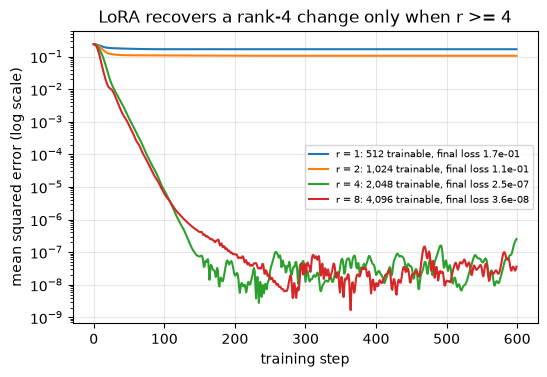

max |adapted - base| at step 0: 0.0
max |adapted - merged| after training (r=8 layer): 2.0265579223632812e-06


In [12]:
torch.manual_seed(0)
d = 256
base = nn.Linear(d, d, bias=False)
U, V = torch.randn(d, 4) / math.sqrt(d), torch.randn(d, 4) / math.sqrt(d)
W_target = base.weight.detach() + U @ V.T * 4                     # the frozen layer plus an exact rank-4 change
X = torch.randn(4096, d)
Y = X @ W_target.T
print(f"dense layer: {d * d:,d} parameters;  size of the change to learn: rank 4")

fig, ax = plt.subplots(figsize=(6, 3.8))
for r in [1, 2, 4, 8]:
    torch.manual_seed(1)
    layer = LoRALinear(copy.deepcopy(base), r=r, alpha=r)          # alpha = r: scale 1
    opt = torch.optim.Adam([layer.A, layer.B], lr=1e-2)
    curve = []
    for step in range(600):
        loss = F.mse_loss(layer(X), Y)
        opt.zero_grad(); loss.backward(); opt.step(); curve.append(loss.item())
    ax.semilogy(curve, label=f"r = {r}: {count_params(layer, True):,d} trainable, final loss {curve[-1]:.1e}")
    print(f"rank {r}: trainable {count_params(layer, True):6,d} ({count_params(layer, True) / (d * d):.1%} of the dense layer)  final loss {curve[-1]:.2e}")
ax.set_xlabel("training step"); ax.set_ylabel("mean squared error (log scale)"); ax.set_title("LoRA recovers a rank-4 change only when r >= 4")
ax.legend(fontsize=7); ax.grid(alpha=0.3); plt.show()

# at initialisation the adapted layer equals the base layer; after training, merging gives the same outputs
fresh = LoRALinear(copy.deepcopy(base), r=4, alpha=4)
print("max |adapted - base| at step 0:", (fresh(X) - fresh.base(X)).abs().max().item())
print("max |adapted - merged| after training (r=8 layer):", (layer(X) - layer.merged()(X)).abs().max().item())

**Reading.** The experiment confirms the premise of LoRA in the controlled case. With rank 1 and rank 2 the loss stalls at 0.17 and 0.11, because a rank-1 or rank-2 matrix simply cannot represent a rank-4 change. At rank 4 the loss falls to 2.5e-7 and at rank 8 to 3.6e-8, using 3.1 % and 6.2 % of the 65,536 parameters of the dense layer. At step 0 the adapted layer is identical to the base one (difference 0.0, because $B=0$), and after training the merged weight reproduces the adapted outputs to 2e-6 (float32 rounding). The catch: here the target is low rank *by construction*; real fine-tuning updates are only approximately low rank, which is why the rank is a hyper-parameter you tune.

### 4.2 LoRA on a real pre-trained model, from scratch and with `peft`

The text experiment of section 3 already used the [`peft`](https://huggingface.co/docs/peft) library (Hugging Face, Apache 2.0) for the `lora` rows: rank 8 on the `query` and `value` projections of every attention layer, plus the classifier. The next cell repeats the same run with **our own** `LoRALinear` and compares the number of trainable parameters and the accuracy; it also checks that `peft`'s `merge_and_unload()` gives back an ordinary model with the same outputs, and measures how big an adapter is on disk compared with a fully fine-tuned model.

In [13]:
own = [run_text("lora", k, lora_impl="own") for k in TXT_SIZES]
peft_rows = txt_df[txt_df.strategy == "lora"].reset_index(drop=True)
cmp = pd.DataFrame({"labelled sentences": [r["n"] for r in own], "own LoRA acc": [r["acc"] for r in own], "peft LoRA acc": peft_rows.acc,
                    "own trainable": [r["trainable"] for r in own], "peft trainable": peft_rows.trainable})
print(cmp.round(3).to_string(index=False))

# merge_and_unload on a peft model: same outputs, no adapter left
from peft import LoraConfig, get_peft_model
torch.manual_seed(0)
enc = get_peft_model(AutoModel.from_pretrained(BERT), LoraConfig(r=8, lora_alpha=16, target_modules=["query", "value"]))
for n_, p in enc.named_parameters():                      # make B non-zero so the merge is a real test
    if "lora_B" in n_: nn.init.normal_(p, std=0.05)
m = TextClf(enc).eval(); b = tokens(te_text[:32])
with torch.no_grad():
    before = m(b)
    m.enc = m.enc.merge_and_unload()
    after = m(b)
print("max |logits before merge - after merge|:", (before - after).abs().max().item(), "| adapter modules left:", sum("lora" in n_ for n_, _ in m.named_modules()))

# storage per task: full model against adapter only
full_mb = size_mb(TEACHER.state_dict())
lora_model = run_text("lora", 2, keep=True)["model"]
adapter_state = {k_: v for k_, v in lora_model.state_dict().items() if "lora_" in k_ or k_.startswith("head")}
print(f"one extra task stored as a full fine-tune: {full_mb:.1f} MB;  as a LoRA adapter (+ classifier): {size_mb(adapter_state):.2f} MB")

 labelled sentences  own LoRA acc  peft LoRA acc  own trainable  peft trainable
                 16         0.653          0.666          34824           34824
                 40         0.766          0.778          34824           34824
                 80         0.778          0.791          34824           34824
                160         0.809          0.831          34824           34824


max |logits before merge - after merge|: 6.854534149169922e-07 | adapter modules left: 0


one extra task stored as a full fine-tune: 44.7 MB;  as a LoRA adapter (+ classifier): 0.15 MB


**Reading.** Our own `LoRALinear` and `peft` have exactly the same number of trainable parameters (34,824: 4 layers x 2 matrices x 8 x (256 + 256) = 32,768 for the adapters plus 2,056 for the classifier) and accuracies that differ by 1 to 2 points (0.653 against 0.666, 0.766 against 0.778, 0.778 against 0.791, 0.809 against 0.831), which is within the noise of different random initialisations. `merge_and_unload()` returns an ordinary model with no adapter modules left and logits that differ by 7e-7. And the storage argument is real: one more task costs 44.7 MB as a full fine-tune and **0.15 MB** as an adapter, 300 times less.

### 4.3 Adapters, QLoRA and other relatives (concepts)

* **Adapters** (Houlsby et al., 2019, [arXiv 1902.00751](https://arxiv.org/abs/1902.00751)) insert a small bottleneck block (down-project, non-linearity, up-project, add back) after each sub-layer and train only those blocks. They work like LoRA in spirit but add layers, so they cannot be merged away and add a little latency.
* **Prompt and prefix tuning** train a few continuous "virtual tokens" prepended to the input and leave every weight untouched.
* **QLoRA** (Dettmers et al., [2023](https://arxiv.org/abs/2305.14314)) combines two ideas from this notebook: the frozen base model is stored in **4 bit** (a data type called NF4, with double quantisation of the scales), and LoRA adapters in 16 bit are trained on top, with gradients flowing *through* the quantised weights. That is what lets a model with tens of billions of parameters be fine-tuned on a single GPU. It needs GPU kernels (the `bitsandbytes` library), so we explain it here and do not run it on this CPU; the 8-bit dynamic quantisation in section 2 is the same idea at lower ambition.
* Rules of thumb: LoRA ranks of 4 to 64 are typical; applying it to more matrices (all attention and feed-forward projections) usually helps more than a larger rank; the learning rate for adapters is roughly 10 times that of full fine-tuning (we used 1e-3 against 1e-4).

### 4.4 Distillation

**Distillation** (Hinton et al., [2015](https://arxiv.org/abs/1503.02531)) trains a small **student** to imitate a large **teacher**. The student does not learn from the hard label ("this is intent 3") but from the teacher's full probability vector: the teacher's softened outputs say which wrong answers are *almost* right, which is information a one-hot label throws away. With a temperature $T$, the teacher's soft targets are $\text{softmax}(z/T)$ for logits $z$, and the student minimises the Kullback-Leibler (KL) divergence to them. DistilBERT of section 2 was made this way.

Distillation is the opposite use of a big model from fine-tuning: you spend the large model once, to label a lot of *unlabelled* text, and ship the small student. We try it on the banking task: the teacher is the fully fine-tuned BERT-Mini (160 labelled sentences), the student is a small network on TF-IDF (term frequency, inverse document frequency) word features, and the student sees the teacher's soft labels on the 740 unlabelled training sentences, never the true labels of those.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
torch.manual_seed(0)
lab_texts, lab_y = txt_subset(20)
lab_set = set(lab_texts)
pool = [t for t in tr_b.text.tolist() if t not in lab_set]                  # unlabelled pool (true labels not used)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(pool + lab_texts)
to_x = lambda ts: torch.tensor(vec.transform(ts).toarray(), dtype=torch.float32)
X_lab, X_pool, X_te = to_x(lab_texts), to_x(pool), to_x(te_text)

TEACHER.eval()
with torch.no_grad():
    T = 2.0
    pool_logits = torch.cat([TEACHER(tokens(pool[i:i + 200])) for i in range(0, len(pool), 200)])
teacher_acc = float((predict(TEACHER, te_text) == te_y).float().mean())
soft = F.softmax(pool_logits / T, dim=1)

def make_student():
    return nn.Sequential(nn.Linear(X_lab.shape[1], 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 8))

def train_student(X, targets, soft_targets, epochs=60):
    torch.manual_seed(0)
    s = make_student(); opt = torch.optim.Adam(s.parameters(), lr=3e-3, weight_decay=1e-4)
    for _ in range(epochs):
        s.train()
        for i in torch.randperm(len(X)).split(64):
            out = s(X[i])
            loss = F.kl_div(F.log_softmax(out / T, 1), targets[i], reduction="batchmean") * T * T if soft_targets else F.cross_entropy(out, targets[i])
            opt.zero_grad(); loss.backward(); opt.step()
    s.eval()
    with torch.no_grad():
        return float((s(X_te).argmax(1) == te_y).float().mean()), count_params(s)

X_small, y_small = to_x(txt_subset(5)[0]), txt_subset(5)[1]
acc_hard, n_student = train_student(X_small, y_small, False)
acc_dist, _ = train_student(X_pool, soft, True)
print(f"teacher (BERT-Mini fine-tuned on 160 sentences): accuracy {teacher_acc:.3f}, {count_params(TEACHER) / 1e6:.1f} M parameters")
print(f"student trained on 40 true labels only (5 per class):      accuracy {acc_hard:.3f}, {n_student / 1e6:.2f} M parameters")
print(f"student distilled from the teacher on {len(pool)} unlabelled sentences: accuracy {acc_dist:.3f}")

teacher (BERT-Mini fine-tuned on 160 sentences): accuracy 0.903, 11.2 M parameters
student trained on 40 true labels only (5 per class):      accuracy 0.753, 0.07 M parameters
student distilled from the teacher on 740 unlabelled sentences: accuracy 0.909


**Reading.** The student with 70 thousand parameters (160 times fewer than the teacher) reaches 0.909 when it imitates the teacher on 740 unlabelled sentences, against 0.753 when it learns from its own 40 true labels (5 per class): 16 points. It matches the teacher (0.903) within noise. Be careful about what is being compared: the teacher was trained on 160 labelled sentences, so the student indirectly profits from labels it never saw, and a bag-of-words student on an easy 8-class task is a friendly case. The result shows the mechanism (a big model turns unlabelled text into training signal for a small one), not a general guarantee.

### 4.5 Quantising the fine-tuned classifier

Section 2 measured quantisation on a pre-trained encoder. The question that matters in practice is whether the *task accuracy* survives. We apply dynamic int8 quantisation to the fine-tuned BERT-Mini classifier and re-measure.

In [15]:
q_clf = torch.ao.quantization.quantize_dynamic(copy.deepcopy(TEACHER), {nn.Linear}, dtype=torch.qint8)
def timed_acc(model):
    t = time.perf_counter(); p = predict(model, te_text); dt = time.perf_counter() - t
    return float((p == te_y).float().mean()), dt
(a32, t32), (a8, t8) = timed_acc(TEACHER), timed_acc(q_clf)
print(f"fp32: accuracy {a32:.3f}, {size_mb(TEACHER.state_dict()):.1f} MB, {t32 * 1000:.0f} ms for 320 sentences")
print(f"int8: accuracy {a8:.3f}, {size_mb(q_clf.state_dict()):.1f} MB, {t8 * 1000:.0f} ms for 320 sentences")

fp32: accuracy 0.903, 44.7 MB, 431 ms for 320 sentences
int8: accuracy 0.903, 35.1 MB, 530 ms for 320 sentences


**Reading.** Accuracy is 0.903 in float32 and 0.903 in int8: no measurable loss. The file shrinks from 44.7 MB to 35.1 MB (not 4x, because the embedding table is not quantised and is a large share of this small model). Speed did **not** improve here: 530 ms for int8 against 431 ms for float32 over the 320 test sentences. For an 11 M-parameter model with 256-wide layers the matrices are so small that the extra work of quantising activations on the fly eats the gain (on an earlier run on a busy laptop int8 was 1.3 times faster; the sign of the effect depends on the hardware). So quantisation here was free in accuracy and modest in size, and a gamble in speed: repeat the measurement on your own model, data and machine, since some layers and tasks tolerate 8 bits much worse than others.

## 5. Saving, loading and exporting models

You have a fine-tuned model; how do you store it, hand it over, resume a stopped run, and serve it somewhere without Python? The basics of `torch.save` are in [Python 1001 section 11](https://python.academy.forwardforecasting.eu/11-ai-frameworks/); here are the points that bite in practice. We use the fully fine-tuned ResNet-18 from section 3.1.

### 5.1 `state_dict` or the whole model, and why pickle is unsafe

`torch.save(model)` pickles the whole Python object, including the *path of its class*: loading it needs the same code at the same import path, and breaks when you refactor. `torch.save(model.state_dict())` stores only a dictionary from parameter names to tensors, and you rebuild the architecture from your own code; that is the portable form.

The deeper problem is that **pickle is a program, not a data format**. Loading a pickle can call any function. A checkpoint from a stranger is therefore the same as running a script from a stranger. The next cell uses a harmless payload (it only prints a sentence) to show that loading *runs code*, and that `torch.load(..., weights_only=True)`, the default since PyTorch 2.6, refuses it.

In [16]:
class Payload:
    def __reduce__(self):                                   # pickle will call print(...) when the file is loaded
        return (print, ("   >>> this line was printed by code inside the 'checkpoint' while it was loading",))

blob = pickle.dumps(Payload())
print("plain pickle.loads:")
pickle.loads(blob)
buf = io.BytesIO(); torch.save(Payload(), buf); buf.seek(0)
try:
    torch.load(buf, weights_only=True)
except Exception as e:
    print("torch.load(weights_only=True) refused it:", type(e).__name__, "-", str(e).splitlines()[0][:110])

# a real checkpoint is just names -> tensors
model_img = IMG_MODELS["full"]
sd = model_img.state_dict()
print("\nstate_dict entries:", len(sd), "| first three:", [(k_, tuple(v.shape)) for k_, v in list(sd.items())[:3]])

plain pickle.loads:
   >>> this line was printed by code inside the 'checkpoint' while it was loading
torch.load(weights_only=True) refused it: UnpicklingError - Weights only load failed. This file can still be loaded, to do so you have two options, do those steps onl

state_dict entries: 122 | first three: [('conv1.weight', (64, 3, 7, 7)), ('bn1.weight', (64,)), ('bn1.bias', (64,))]


### 5.2 safetensors

[**safetensors**](https://github.com/huggingface/safetensors) (Hugging Face, Apache 2.0, [docs](https://huggingface.co/docs/safetensors)) is a file format that is *only* tensors: an 8-byte length, a JSON header with names, shapes and offsets, then raw bytes. There is nothing to execute, the header can be read without loading the data, and single tensors can be read lazily from disk. It is the default format for new checkpoints on the Hub and what you should prefer when you publish.

In [17]:
from safetensors.torch import save_file, load_file
from safetensors import safe_open
tmp = tempfile.mkdtemp()
path_st, path_pt = os.path.join(tmp, "resnet18_fmnist.safetensors"), os.path.join(tmp, "resnet18_fmnist.pt")
save_file({k_: v.contiguous() for k_, v in sd.items()}, path_st); torch.save(sd, path_pt)
loaded = load_file(path_st)
print("identical tensors after the round trip:", all(torch.equal(loaded[k_], v) for k_, v in sd.items()))
print(f"file sizes: safetensors {os.path.getsize(path_st) / 1e6:.2f} MB, torch.save {os.path.getsize(path_pt) / 1e6:.2f} MB")
with open(path_st, "rb") as f:
    n = int.from_bytes(f.read(8), "little"); header = json.loads(f.read(n))
print("header (read without loading any weight):", {k_: header[k_] for k_ in list(header)[:2]})
with safe_open(path_st, framework="pt") as f:
    print("lazy read of one tensor, fc.weight:", tuple(f.get_tensor("fc.weight").shape))

identical tensors after the round trip: True
file sizes: safetensors 44.78 MB, torch.save 44.81 MB
header (read without loading any weight): {'bn1.num_batches_tracked': {'dtype': 'I64', 'shape': [], 'data_offsets': [0, 8]}, 'layer1.0.bn1.num_batches_tracked': {'dtype': 'I64', 'shape': [], 'data_offsets': [8, 16]}}
lazy read of one tensor, fc.weight: (10, 512)


### 5.3 Checkpoints that resume training

A file with only the weights can *serve* a model but cannot *continue training* it: Adam keeps per-weight moment estimates, the learning-rate schedule has a position, and the random generators decide the shuffling and the dropout masks. A resumable checkpoint stores all of them. We verify it the only convincing way: train 6 epochs in one go, and train 3 epochs, save, rebuild everything from scratch, load, and train 3 more. The final weights must be identical.

In [18]:
def build():
    torch.manual_seed(0)
    m = nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 1))
    return m, torch.optim.Adam(m.parameters(), lr=1e-2)
Xr, yr = torch.randn(256, 20), torch.randn(256, 1)

def train_epochs(m, opt, epochs):
    for _ in range(epochs):
        m.train()
        for i in torch.randperm(256).split(64):                   # uses the global RNG: shuffling and dropout
            loss = F.mse_loss(m(Xr[i]), yr[i]); opt.zero_grad(); loss.backward(); opt.step()

m1, o1 = build(); torch.manual_seed(5); train_epochs(m1, o1, 6)

m2, o2 = build(); torch.manual_seed(5); train_epochs(m2, o2, 3)
ckpt_path = os.path.join(tmp, "ckpt.pt")
torch.save({"model": m2.state_dict(), "optimizer": o2.state_dict(), "epoch": 3, "rng": torch.get_rng_state()}, ckpt_path)
m3, o3 = build()                                                  # a fresh process would start here
ck = torch.load(ckpt_path, weights_only=True)
m3.load_state_dict(ck["model"]); o3.load_state_dict(ck["optimizer"]); torch.set_rng_state(ck["rng"])
train_epochs(m3, o3, 3)
print("largest weight difference, 6 epochs in one go vs 3 + resume + 3:", max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m3.parameters())))

m4, o4 = build(); m4.load_state_dict(ck["model"]); torch.manual_seed(5); train_epochs(m4, o4, 3)       # weights only: fresh Adam state
print("largest difference if only the weights were saved (optimizer and RNG lost):", max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m4.parameters())))

largest weight difference, 6 epochs in one go vs 3 + resume + 3: 0.0
largest difference if only the weights were saved (optimizer and RNG lost): 0.10296713560819626


### 5.4 Exporting to ONNX and checking it

[**ONNX**](https://onnx.ai) (Open Neural Network Exchange) is an open format for the *computation graph* plus weights, so a model trained in PyTorch can be served by [ONNX Runtime](https://onnxruntime.ai) from C++, Java, JavaScript or a phone, with no Python and no PyTorch. Exporting is one call; the part people forget is **checking** it: run both models on the same inputs and compare. We also declare the batch dimension dynamic, otherwise the exported graph only accepts the batch size you traced it with.

In [19]:
import onnx, onnxruntime as ort
model_img.eval()
onnx_path = os.path.join(tmp, "resnet18_fmnist.onnx")
sample = Xte_img[:2]
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    torch.onnx.export(model_img, (sample,), onnx_path, input_names=["image"], output_names=["logits"],
                      dynamic_shapes={"x": {0: torch.export.Dim("batch")}})
onnx.checker.check_model(onnx.load(onnx_path))
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
with torch.no_grad():
    ref_logits = model_img(Xte_img).numpy()
ort_logits = sess.run(None, {"image": Xte_img.numpy()})[0]
onnx_mb = sum(os.path.getsize(os.path.join(tmp, f_)) for f_ in os.listdir(tmp) if f_.startswith("resnet18_fmnist.onnx")) / 1e6
print(f"ONNX export: {onnx_mb:.1f} MB (graph + weights, the weights may sit in a companion .data file)")
print("max |PyTorch logits - ONNX Runtime logits| over 1000 test images:", float(np.abs(ref_logits - ort_logits).max()))
print("same predicted class on all test images:", bool((ref_logits.argmax(1) == ort_logits.argmax(1)).all()), "| accuracy", float((ort_logits.argmax(1) == yte_img.numpy()).mean()))
print("a batch size never seen at export time (batch of 7) works:", sess.run(None, {"image": Xte_img[:7].numpy()})[0].shape)
def bench(f, reps=5):
    f(); ts = []
    for _ in range(reps):
        t = time.perf_counter(); f(); ts.append(time.perf_counter() - t)
    return np.median(ts) * 1000
xb = Xte_img[:100]
with torch.no_grad():
    print(f"latency for 100 images: PyTorch {bench(lambda: model_img(xb)):.0f} ms, ONNX Runtime {bench(lambda: sess.run(None, {'image': xb.numpy()})):.0f} ms")

ONNX export: 44.8 MB (graph + weights, the weights may sit in a companion .data file)
max |PyTorch logits - ONNX Runtime logits| over 1000 test images: 3.153085708618164e-05
same predicted class on all test images: True | accuracy 0.689
a batch size never seen at export time (batch of 7) works: (7, 10)


latency for 100 images: PyTorch 106 ms, ONNX Runtime 89 ms


### 5.5 Writing a model card

The last artefact is the card that travels with the file. The honest card states what the model was fine-tuned from (and under which licence), on what data, how it was measured and, above all, what it must not be used for. We generate it from the numbers we just measured, so the card cannot drift away from the results, and parse it with the Hub's own `ModelCard` class to check the metadata header is valid.

In [20]:
from huggingface_hub import ModelCard
acc_full = float(img_df[(img_df.strategy == "full") & (img_df.n == 300)].acc.iloc[0])
card_text = f'''---
language: en
license: other
license_name: imagenet-non-commercial-research
library_name: pytorch
base_model: torchvision/resnet18
datasets:
- zalando-datasets/fashion_mnist
metrics:
- accuracy
tags:
- image-classification
- transfer-learning
---

# resnet18-fashion-mnist-300 (teaching model)

ResNet-18 with ImageNet weights (torchvision `IMAGENET1K_V1`), fully fine-tuned on **300 labelled images** of Fashion-MNIST (30 per class, upsampled to 48x48).

## Intended use
Classroom demonstration of transfer learning. **Not** for any production or commercial use.

## Data and licences
* Base weights: trained on ImageNet, whose terms restrict use to non-commercial research and education. This model inherits that restriction.
* Fine-tuning data: Fashion-MNIST (MIT licence), 300 images, seed 0.

## Evaluation
Accuracy {acc_full:.3f} on 1000 held-out Fashion-MNIST test images (100 per class). One run, one seed: differences of 2 to 3 points between runs are expected.

## Limitations
Trained on 28x28 grey product pictures; it will not work on photographs of people wearing clothes. No fairness analysis was done. Exported to ONNX and checked against PyTorch (largest logit difference below 1e-3).
'''
card = ModelCard(card_text)
print("metadata parsed by the Hub library:", {k_: card.data.to_dict()[k_] for k_ in ["license", "base_model", "datasets"]})
print(card_text[:900] + "...")

metadata parsed by the Hub library: {'license': 'other', 'base_model': 'torchvision/resnet18', 'datasets': ['zalando-datasets/fashion_mnist']}
---
language: en
license: other
license_name: imagenet-non-commercial-research
library_name: pytorch
base_model: torchvision/resnet18
datasets:
- zalando-datasets/fashion_mnist
metrics:
- accuracy
tags:
- image-classification
- transfer-learning
---

# resnet18-fashion-mnist-300 (teaching model)

ResNet-18 with ImageNet weights (torchvision `IMAGENET1K_V1`), fully fine-tuned on **300 labelled images** of Fashion-MNIST (30 per class, upsampled to 48x48).

## Intended use
Classroom demonstration of transfer learning. **Not** for any production or commercial use.

## Data and licences
* Base weights: trained on ImageNet, whose terms restrict use to non-commercial research and education. This model inherits that restriction.
* Fine-tuning data: Fashion-MNIST (MIT licence), 300 images, seed 0.

## Evaluation
Accuracy 0.689 on 1000 held-out Fashion-MN

**Reading.** Plain `pickle.loads` executed the line of code hidden in the "checkpoint", while `torch.load(weights_only=True)` refused it. safetensors reproduced every tensor exactly at the same size as the pickle format (44.8 MB), and its header could be read without touching a weight. The resumable checkpoint gave final weights that differ by exactly 0.0 from the uninterrupted run, whereas saving only the weights (losing Adam's state and the random generators) ended 0.10 away, a visible difference. ONNX Runtime matched PyTorch to 3e-5 in the logits, predicted the same class on all 1000 images, reached the same accuracy (0.689), and accepted a batch size unseen at export. It was a little faster than PyTorch here (89 ms against 106 ms for 100 images), but do not count on that: the main gain of export is portability (no Python needed).

## 6. A decision guide

Start at the top and stop at the first option that meets your requirement; each step down costs more data, compute and maintenance.

| Option | Use it when | Needs | Cost | Evidence in this notebook |
|---|---|---|---|---|
| **1. Use a model as is** | a published model already does your task, in your domain, well enough on *your* test set | a test set of your own | lowest | the zero-shot and probe rows are the floor to beat |
| **2. Prompt it** (language models) | the task can be described in words, with a few examples in the prompt | an instruction-tuned model; see [RAG systems](https://rag-systems.academy.forwardforecasting.eu/) | per-call cost, no training | not run here (needs a large model) |
| **3. Linear probe** on frozen features | very few labels (tens), or you need many tasks on one backbone | a good backbone, a few seconds | tiny | best or tied for best up to about 100 labels in both tasks (sections 3.1, 3.2) |
| **4. LoRA or other PEFT** | a few hundred to millions of labels; one base, many tasks; limited memory | the base weights, a GPU for large models | small, adapters of megabytes | best or tied at 16 to 80 labels with 0.3 % of the parameters, 7 points behind full fine-tuning at 160 (sections 3.2, 4) |
| **5. Full fine-tune** | plenty of labels, the domain is far from pre-training, you can store one copy per task | memory for weights plus optimiser | high | won only at the largest text size (160 labels); lost on the image task (section 3) |
| **6. Train from scratch** | no suitable checkpoint exists, or licences forbid every one, and you have a lot of data | a lot of data and compute | highest | the red curve of section 3.1: behind the probe with few labels, level with it at 300 |

Two questions come before the table: *how many labels do I have, and are they like the pre-training data?* and *how will I measure success, on data the model has not seen?* A decision made without a held-out test set is a guess.

### Licence and safety checklist

Before you build on a checkpoint:

1. **Licence of the weights**: read it. Commercial use allowed? Thresholds, field-of-use limits, naming or attribution rules? Does it bind the people you pass the model to?
2. **Licence of the data it was trained on** and of **your fine-tuning data**: a non-commercial dataset taints the result.
3. **Provenance**: who published it, is the repository the official one, is there a model card, a dataset card, and a hash or signature you can check?
4. **Format**: prefer safetensors or ONNX; load pickles only from sources you trust, with `weights_only=True`; never `trust_remote_code=True` without reading the code.
5. **Evaluation on your data**: the card's accuracy is on somebody else's data. Report variance, not one number.
6. **Known limits and misuse**: bias, languages covered, out-of-scope uses; write them into your own model card.
7. **Reproducibility**: record the exact checkpoint revision (commit hash), the seed, the library versions; pin them.
8. **Privacy and leaks**: a fine-tuned model can memorise its training examples; do not fine-tune on data you cannot share with whoever can query the model.

## Key takeaways

* **"Open" is three questions**: are the code, the weights and the data open, and under which licence? Open weights are not the same as open source, and the licence of a checkpoint is inherited by everything you build on it.
* **Precision is a dial.** Dynamic int8 quantisation shrinks the Linear-layer weights 4x with no training (the whole file only 2x here, since embeddings stay in float32), and the speed-up (or even slow-down) of bf16 and int8 depends on the CPU; check size, speed and *task accuracy* on your own data.
* **Transfer learning is a ladder, and where you stand depends on the number of labels.** With a handful of labels a linear probe is hard to beat (it was best or tied in both tasks); full fine-tuning paid off only at the largest text size and hurt on the domain-shifted image task; pre-training mattered most with the fewest labels.
* **LoRA** trains a low-rank correction: the trainable parameters shrink by about 300 times (34,824 against 11.2 M here), the adapter is 0.15 MB per task, and it merges into the weights for free inference.
* **Distillation** spends a big model once to teach a small one; QLoRA fine-tunes a 4-bit base with LoRA adapters; both are the same two ideas (low bits, low rank) pushed further.
* **Save with safetensors or `state_dict`, never unpickle strangers**; a resumable checkpoint needs the optimiser and the random state; an exported ONNX model must be checked against the original.
* **A model card is part of the model.** Write the licence, the data, the measured results and the limits next to the weights.

## Exercises

1. In section 3.1 change the image size from 48 to 96 (training is about four times slower). Does the ranking of the strategies change? Which one gains most?
2. Run the image comparison with three seeds and plot the mean and the spread. Which differences in the plots survive?
3. Unfreeze `layer3` and `layer4` in the image task. Is there a number of labels at which it beats `layer4` only?
4. In the text task, apply LoRA to all four attention projections (`query`, `key`, `value` and the output dense layer) and to the feed-forward layers. Does accuracy improve more than by raising the rank from 8 to 32?
5. Change the LoRA rank in section 4.2 to 1, 4, 16 and 64 and plot accuracy against trainable parameters. Where is the knee?
6. Implement the adapter of Houlsby et al. (a bottleneck block after each attention output) and compare it with LoRA at the same parameter count.
7. Quantise only the feed-forward layers, then only the attention layers. Which one tolerates int8 better?
8. Distil with temperatures 1, 2 and 5 in section 4.4. Does the student gain or lose accuracy, and why?
9. Export the text classifier to ONNX with a dynamic sequence length and check the outputs with ONNX Runtime. What does the tokeniser have to do outside the graph?
10. Write the model card for the text classifier and pick its licence carefully: which licences does it inherit from?

## References

* Hu, E. J. et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
* Dettmers, T. et al. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* [arXiv:2305.14314](https://arxiv.org/abs/2305.14314)
* Hinton, G., Vinyals, O., Dean, J. (2015). *Distilling the Knowledge in a Neural Network.* [arXiv:1503.02531](https://arxiv.org/abs/1503.02531)
* Yosinski, J., Clune, J., Bengio, Y., Lipson, H. (2014). *How transferable are features in deep neural networks?* [arXiv:1411.1792](https://arxiv.org/abs/1411.1792)
* Howard, J., Ruder, S. (2018). *Universal Language Model Fine-tuning for Text Classification* (ULMFiT). [arXiv:1801.06146](https://arxiv.org/abs/1801.06146)
* Mitchell, M. et al. (2019). *Model Cards for Model Reporting.* FAT* 2019, [arXiv:1810.03993](https://arxiv.org/abs/1810.03993)
* Houlsby, N. et al. (2019). *Parameter-Efficient Transfer Learning for NLP.* [arXiv:1902.00751](https://arxiv.org/abs/1902.00751)
* Sanh, V. et al. (2019). *DistilBERT, a distilled version of BERT.* [arXiv:1910.01108](https://arxiv.org/abs/1910.01108)
* Turc, I. et al. (2019). *Well-Read Students Learn Better: On the Importance of Pre-training Compact Models.* [arXiv:1908.08962](https://arxiv.org/abs/1908.08962)
* He, K. et al. (2015). *Deep Residual Learning for Image Recognition.* [arXiv:1512.03385](https://arxiv.org/abs/1512.03385)
* Xiao, H., Rasul, K., Vollgraf, R. (2017). *Fashion-MNIST.* [arXiv:1708.07747](https://arxiv.org/abs/1708.07747), data under MIT licence: [dataset card](https://huggingface.co/datasets/zalando-datasets/fashion_mnist)
* Casanueva, I. et al. (2020). *Efficient Intent Detection with Dual Sentence Encoders* (Banking77). [arXiv:2003.04807](https://arxiv.org/abs/2003.04807), CC BY 4.0: [dataset card](https://huggingface.co/datasets/PolyAI/banking77)
* Open Source Initiative (2024). [*The Open Source AI Definition 1.0*](https://opensource.org/ai/open-source-ai-definition)
* Tools: [Hugging Face Transformers and Hub](https://huggingface.co/docs/hub/model-cards), [PEFT](https://huggingface.co/docs/peft), [safetensors](https://github.com/huggingface/safetensors), [ONNX](https://onnx.ai), [ONNX Runtime](https://onnxruntime.ai), [torchvision ResNet-18](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
* Sibling course: [Python 1001, AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/)

In [21]:
print(f"total notebook run time: {(time.time() - T_START) / 60:.1f} minutes")

total notebook run time: 2.6 minutes
